In [4]:
!pip install -q sktime psutil

In [5]:
from google.colab import drive
drive.mount('/content/drive')
import os
DATA_DIR = '/content/drive/MyDrive/diss-datasets'
print(os.listdir(DATA_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['MP8.npy', 'Rowing.npy', 'MP50.npy', 'CMJ_text_embeddings_train.npy', 'CMJ_text_embeddings_test.npy', 'CMJ_text_results.txt', 'MP8_text_embeddings_train.npy', 'MP8_text_embeddings_test.npy', 'MP8_text_results.txt', 'MP50_text_embeddings_train.npy', 'MP50_text_embeddings_test.npy', 'MP50_text_results.txt', 'SYNTH_text_embeddings_train.npy', 'SYNTH_text_embeddings_test.npy', 'SYNTH_text_results.txt', 'Rowing_text_embeddings_train.npy', 'Rowing_text_embeddings_test.npy', 'Rowing_text_results.txt', 'chbmit_parts', 'CHBMIT_crosspatient.npy', 'Chronos2_CHBMIT_train_emb.npy', 'Chronos2_CHBMIT_test_emb.npy', 'Chronos2_CHBMIT_perm_train_emb.npy', 'Chronos2_CHBMIT_perm_test_emb.npy', 'Chronos2_CHBMIT_desync_train_emb.npy', 'Chronos2_CHBMIT_desync_test_emb.npy', 'MantisV2_CHBMIT_train_emb.npy', 'Chronos2_CHBMIT_chanpool_train_emb.npy', 'Chronos2_CHBMIT_chanpool_test_em

In [6]:
import numpy as np, pandas as pd, gc, time
from sktime.transformations.panel.rocket import MiniRocketMultivariate, MiniRocket
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score, f1_score

ALPHAS = np.logspace(-3, 3, 10)

DATASETS = {
    'CMJ': 'CMJ.npy', 'MP8': 'MP8.npy', 'MP50': 'MP50.npy',
    'Rowing': 'Rowing.npy', 'SYNTH': 'SYNTH.npy',
    'CHB-MIT': 'CHBMIT_crosspatient.npy',
}

def load(fname):
    d = np.load(f'{DATA_DIR}/{fname}', allow_pickle=True).item()
    return (d['train']['X'].astype(np.float32),
            np.array([int(v) for v in d['train']['y']]),
            d['test']['X'].astype(np.float32),
            np.array([int(v) for v in d['test']['y']]))

def fit_scores(ftr, ytr, fte, yte):
    clf = RidgeClassifierCV(alphas=ALPHAS).fit(ftr, ytr)
    pred = clf.predict(fte)
    return accuracy_score(yte, pred), f1_score(yte, pred, average='macro')

In [7]:
def multivariate(Xtr, ytr, Xte, yte, nk):
    r = MiniRocketMultivariate(num_kernels=nk).fit(Xtr)
    ftr = np.ascontiguousarray(r.transform(Xtr), dtype=np.float32)
    fte = np.ascontiguousarray(r.transform(Xte), dtype=np.float32)
    del r; gc.collect()
    return fit_scores(ftr, ytr, fte, yte)

def per_channel(Xtr, ytr, Xte, yte, nk):
    accs, ftr_all, fte_all = [], [], []
    for ch in range(Xtr.shape[1]):
        r = MiniRocket(num_kernels=nk)
        a = np.ascontiguousarray(Xtr[:, ch:ch+1, :])
        b = np.ascontiguousarray(Xte[:, ch:ch+1, :])
        r.fit(a)
        ft = np.ascontiguousarray(r.transform(a), dtype=np.float32)
        fe = np.ascontiguousarray(r.transform(b), dtype=np.float32)
        accs.append(fit_scores(ft, ytr, fe, yte)[0])
        ftr_all.append(ft); fte_all.append(fe)
        del r, a, b; gc.collect()
    concat = fit_scores(np.concatenate(ftr_all, 1), ytr,
                        np.concatenate(fte_all, 1), yte)
    del ftr_all, fte_all; gc.collect()
    return accs, concat

In [8]:
KERNELS = {'CMJ': 9996, 'MP8': 9996, 'SYNTH': 9996,
           'Rowing': 2016, 'MP50': 2016, 'CHB-MIT': 2016}

RESULTS_PATH = f'{DATA_DIR}/rocket_gaps_fixed_kernels.csv'
done = set()
if os.path.exists(RESULTS_PATH):
    prev = pd.read_csv(RESULTS_PATH)
    done = set(prev['dataset'])
    print('resuming, done:', done)

In [9]:
rows = [] if not done else pd.read_csv(RESULTS_PATH).to_dict('records')
for name, fname in DATASETS.items():
    if name in done:
        print(name, 'skipped'); continue
    print(f'\n=== {name} ===')
    Xtr, ytr, Xte, yte = load(fname)
    nk = KERNELS[name]
    nch = Xtr.shape[1]
    print(f'  channels {nch}  kernels {nk} (fixed across variants)')
    t0 = time.time()
    mv_acc, mv_f1 = multivariate(Xtr, ytr, Xte, yte, nk)
    accs, (cc_acc, cc_f1) = per_channel(Xtr, ytr, Xte, yte, nk)
    best = max(accs); best_ch = int(np.argmax(accs))
    row = dict(dataset=name, channels=nch, kernels=nk,
               multivariate_acc=mv_acc, multivariate_f1=mv_f1,
               best_channel_acc=best, best_ch_idx=best_ch,
               concat_acc=cc_acc, concat_f1=cc_f1,
               gap_best=mv_acc-best, gap_concat=mv_acc-cc_acc,
               seconds=time.time()-t0)
    rows.append(row)
    pd.DataFrame(rows).to_csv(RESULTS_PATH, index=False)
    print(f'  multivariate       {mv_acc:.4f}')
    print(f'  best channel       {best:.4f}  (ch {best_ch})')
    print(f'  concat independent {cc_acc:.4f}')
    print(f'  gap best-channel   {mv_acc-best:+.4f}')
    print(f'  gap concat         {mv_acc-cc_acc:+.4f}')
    del Xtr, ytr, Xte, yte; gc.collect()
print('\ndone')


=== CMJ ===
  channels 3  kernels 9996 (fixed across variants)
  multivariate       0.9497
  best channel       0.9330  (ch 2)
  concat independent 0.9497
  gap best-channel   +0.0168
  gap concat         +0.0000

=== MP8 ===
  channels 8  kernels 9996 (fixed across variants)
  multivariate       0.7261
  best channel       0.5849  (ch 4)
  concat independent 0.6975
  gap best-channel   +0.1412
  gap concat         +0.0286

=== MP50 ===
  channels 50  kernels 2016 (fixed across variants)
  multivariate       0.7681
  best channel       0.6437  (ch 3)
  concat independent 0.7529
  gap best-channel   +0.1244
  gap concat         +0.0151

=== Rowing ===
  channels 45  kernels 2016 (fixed across variants)
  multivariate       0.7750
  best channel       0.5395  (ch 25)
  concat independent 0.7961
  gap best-channel   +0.2355
  gap concat         -0.0211

=== SYNTH ===
  channels 8  kernels 9996 (fixed across variants)
  multivariate       0.8780
  best channel       0.6090  (ch 1)
  conca

In [10]:
R = pd.read_csv(RESULTS_PATH)
order = ['MP50', 'CHB-MIT', 'MP8', 'Rowing', 'CMJ', 'SYNTH']
R = R.set_index('dataset').reindex(order).reset_index()
print(R[['dataset', 'channels', 'multivariate_acc', 'best_channel_acc',
         'concat_acc', 'gap_best', 'gap_concat']].round(4).to_string(index=False))

dataset  channels  multivariate_acc  best_channel_acc  concat_acc  gap_best  gap_concat
   MP50        50            0.7681            0.6437      0.7529    0.1244      0.0151
CHB-MIT        18            0.8774            0.8640      0.8736    0.0134      0.0038
    MP8         8            0.7261            0.5849      0.6975    0.1412      0.0286
 Rowing        45            0.7750            0.5395      0.7961    0.2355     -0.0211
    CMJ         3            0.9497            0.9330      0.9497    0.0168      0.0000
  SYNTH         8            0.8780            0.6090      0.8860    0.2690     -0.0080


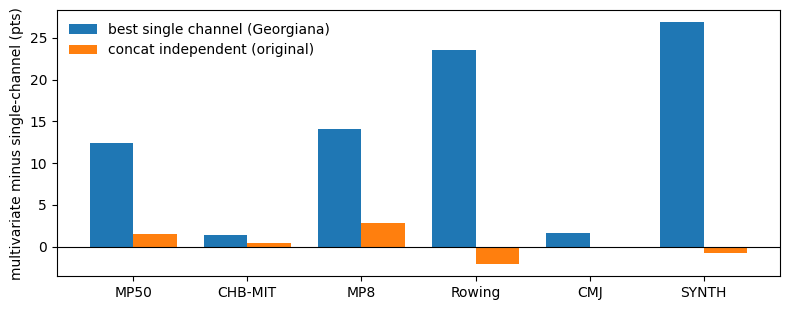

In [11]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(R)); w = 0.38
ax.bar(x - w/2, R['gap_best']*100, w, label='best single channel (Georgiana)')
ax.bar(x + w/2, R['gap_concat']*100, w, label='concat independent (original)')
ax.axhline(0, lw=0.8, color='k')
ax.set_xticks(x); ax.set_xticklabels(R['dataset'])
ax.set_ylabel('multivariate minus single-channel (pts)')
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(f'{DATA_DIR}/gap_comparison.png', dpi=150)
plt.show()

In [13]:
import os
for p in ['/content/drive/MyDrive/results.xlsx',
          '/content/drive/MyDrive/diss-datasets/results.xlsx']:
    print(p, os.path.exists(p))

/content/drive/MyDrive/results.xlsx True
/content/drive/MyDrive/diss-datasets/results.xlsx False


In [14]:
import shutil
XLSX = '/content/drive/MyDrive/results.xlsx'
shutil.copy(XLSX, '/content/drive/MyDrive/results_backup_prefixedkernel.xlsx')
print('backed up')

backed up


In [15]:
from openpyxl import load_workbook

XLSX = '/content/drive/MyDrive/results.xlsx'
SHEET = 'Rocket fixed-kernel'

out = R[['dataset', 'channels', 'kernels', 'multivariate_acc',
         'best_channel_acc', 'best_ch_idx', 'concat_acc',
         'gap_best', 'gap_concat']].copy()
out.columns = ['Dataset', 'Channels', 'Kernels', 'Multivariate',
               'Best single channel', 'Best ch idx', 'Concat independent',
               'Gap (MV - best ch)', 'Gap (MV - concat)']

with pd.ExcelWriter(XLSX, engine='openpyxl', mode='a',
                    if_sheet_exists='replace') as writer:
    out.to_excel(writer, sheet_name=SHEET, index=False, startrow=2)

wb = load_workbook(XLSX)
wb[SHEET]['A1'] = 'Fixed-kernel channel-dependency gap (best-channel + concat), MiniRocket'
wb.save(XLSX)
print('added sheet:', SHEET)
print('existing sheets:', load_workbook(XLSX).sheetnames)

added sheet: Rocket fixed-kernel
existing sheets: ['Accuracy', 'CHB-MIT ablations', 'Dataset', 'Rocket', 'RQ3 event sensitivity', 'TiViT backbone comparison', 'RQ1 event-level ablations', 'RQ1 MOMENT ablations', 'RQ4 retrofitting', 'SigLIP2 per-channel', 'SigLIP2 stacked', 'SigLIP2 fused', 'LLM-ABBA', 'Dataset summary', 'Rocket fixed-kernel']
